# Projet 12: détéction de faux billets

## <span style="color: MediumSeaGreen;">     1- Préparation des données </span>

### <span style="color: MediumSeaGreen;"> - Importation des données et des bibliothèques </span>

In [1]:
# pour enlever le warning de k-means
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("billets.csv", sep=";")

df.head(3)

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16


In [3]:
print(df.shape)
print(df.info())
#display(df.head())

(1500, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   is_genuine    1500 non-null   bool   
 1   diagonal      1500 non-null   float64
 2   height_left   1500 non-null   float64
 3   height_right  1500 non-null   float64
 4   margin_low    1463 non-null   float64
 5   margin_up     1500 non-null   float64
 6   length        1500 non-null   float64
dtypes: bool(1), float64(6)
memory usage: 71.9 KB
None


In [4]:
print("Dimensions :", df.shape)

print("\nTypes des variables :")
print(df.dtypes)

print("\nValeurs manquantes :")
print(df.isna().sum())

print("\nDoublons :", df.duplicated().sum())

print("\nRépartition vrais / faux :")
print(df["is_genuine"].value_counts())

Dimensions : (1500, 7)

Types des variables :
is_genuine         bool
diagonal        float64
height_left     float64
height_right    float64
margin_low      float64
margin_up       float64
length          float64
dtype: object

Valeurs manquantes :
is_genuine       0
diagonal         0
height_left      0
height_right     0
margin_low      37
margin_up        0
length           0
dtype: int64

Doublons : 0

Répartition vrais / faux :
is_genuine
True     1000
False     500
Name: count, dtype: int64


In [ ]:
df.describe()

### <span style="color: MediumSeaGreen;">Découpage des données et variables</span>

La **variable expliqué (y)** est "is_genuine" et les autres sont des **variables explicatives (X)**

In [5]:
X = df.drop(columns="is_genuine")

y = df["is_genuine"]

print(X.shape)
print(y.shape)

display(X.head())
display(y.head())

(1500, 6)
(1500,)


,diagonal,height_left,height_right,margin_low,margin_up,length
0,171.81,104.86,104.95,4.52,2.89,112.83
1,171.46,103.36,103.66,3.77,2.99,113.09
2,172.69,104.48,103.50,4.40,2.94,113.16
3,171.36,103.91,103.94,3.62,3.01,113.51
4,171.73,104.28,103.46,4.04,3.48,112.54


0    True
1    True
2    True
3    True
4    True
Name: is_genuine, dtype: bool

On sépare les données en deux groupes: **train (80%)** et **test (20%)**

Utiliser stratify=y, parce que notre population est déséquilibrée à 2/3 vrais, 1/3 faux. Cela permet de **conserver cette même proportion dans train et test**

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (1200, 6)
X_test  : (300, 6)
y_train : (1200,)
y_test  : (300,)


In [7]:
print("TRAIN")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nTEST")
print(y_test.value_counts())

print(y_test.value_counts(normalize=True))

TRAIN
is_genuine
True     800
False    400
Name: count, dtype: int64
is_genuine
True     0.666667
False    0.333333
Name: proportion, dtype: float64

TEST
is_genuine
True     200
False    100
Name: count, dtype: int64
is_genuine
True     0.666667
False    0.333333
Name: proportion, dtype: float64


### <span style="color: MediumSeaGreen;">Les valeurs manquantes</span>

On traite les **valeurs manquantes de margin_low** sans toucher au jeu de test pour calculer l’imputation.
**Imputation par la médiane** : on ne perd aucun billet, et la médiane est peu sensible à d’éventuelles valeurs extrêmes.
Commencer par vérifier la médiane uniquement sur le jeu d’entraînement :

In [8]:
print("Valeurs manquantes dans X_train :")
print(X_train.isna().sum())

print("\nValeurs manquantes dans X_test :")
print(X_test.isna().sum())

print("\nMédiane de margin_low sur le train :")
print(X_train["margin_low"].median())

Valeurs manquantes dans X_train :
diagonal         0
height_left      0
height_right     0
margin_low      25
margin_up        0
length           0
dtype: int64

Valeurs manquantes dans X_test :
diagonal         0
height_left      0
height_right     0
margin_low      12
margin_up        0
length           0
dtype: int64

Médiane de margin_low sur le train :
4.32


Puis, utiliser SimpleImputer. C’est préférable à un fillna() manuel, car on pourra réutiliser exactement le même mécanisme plus tard dans notre application finale.

In [9]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

On apprend la médiane sur les 1 200 billets d'entraînement, puis on applique cette même valeur aux 300 billets de test. On ne laisse donc pas le jeu de test apporter de l'information à l'entraînement.

In [10]:
print(X_train_imputed.isna().sum())
print()
print(X_test_imputed.isna().sum())

diagonal        0
height_left     0
height_right    0
margin_low      0
margin_up       0
length          0
dtype: int64

diagonal        0
height_left     0
height_right    0
margin_low      0
margin_up       0
length          0
dtype: int64


La variable margin_low comportait quelques valeurs manquantes. J'ai choisi une **imputation par la médiane** afin de conserver les observations et de limiter l'influence d'éventuelles valeurs extrêmes. La valeur d'imputation a été **calculée uniquement sur le jeu d'entraînement** afin d'éviter toute fuite d'information vers le jeu de test.**

la division et nettoyage terminés, on passe à l'analyse exploratoire

## <span style="color: DarkOrange;"> 2 - Analyse exploratoire </span>

eda: Exploratory Data Analysis

J'utilise les données de train pour l'analyse exploratoire

In [15]:
# combiner X et y pour avoir l'ensemble des données de train
eda = X_train_imputed.copy()

eda["is_genuine"] = y_train
eda["type_billet"] = np.where(
    eda["is_genuine"],
    "Vrai",
    "Faux"
)

eda.head()

,diagonal,height_left,height_right,margin_low,margin_up,length,is_genuine,type_billet
122,171.81,103.22,103.92,3.99,3.06,113.32,True,Vrai
875,171.94,104.09,103.28,3.98,3.13,113.53,True,Vrai
941,172.13,103.35,104.17,4.23,3.27,113.06,True,Vrai
494,172.08,104.19,104.03,4.11,2.99,113.50,True,Vrai
186,172.21,103.48,104.04,4.40,3.00,113.15,True,Vrai


In [12]:
X_train.head()

,diagonal,height_left,height_right,margin_low,margin_up,length
122,171.81,103.22,103.92,3.99,3.06,113.32
875,171.94,104.09,103.28,3.98,3.13,113.53
941,172.13,103.35,104.17,4.23,3.27,113.06
494,172.08,104.19,104.03,4.11,2.99,113.50
186,172.21,103.48,104.04,4.40,3.00,113.15


In [13]:
X_train.shape

(1200, 6)

In [14]:
eda.shape

(1200, 8)

In [16]:
features = [
    "diagonal",
    "height_left",
    "height_right",
    "margin_low",
    "margin_up",
    "length"
]

eda.groupby("type_billet")[features].mean().round(3)

,diagonal,height_left,height_right,margin_low,margin_up,length
type_billet,,,,,,
Faux,171.899,104.187,104.140,5.201,3.350,111.617
Vrai,171.990,103.954,103.809,4.131,3.053,113.194


Sur ce jeu de données, les variables qui semblent le plus différencier les deux catégories sont notamment **length, margin_low et margin_up**. La diagonale, elle, paraît beaucoup moins discriminante. Ce n’est encore qu’une observation descriptive à ce stade.

In [17]:
import seaborn as sns

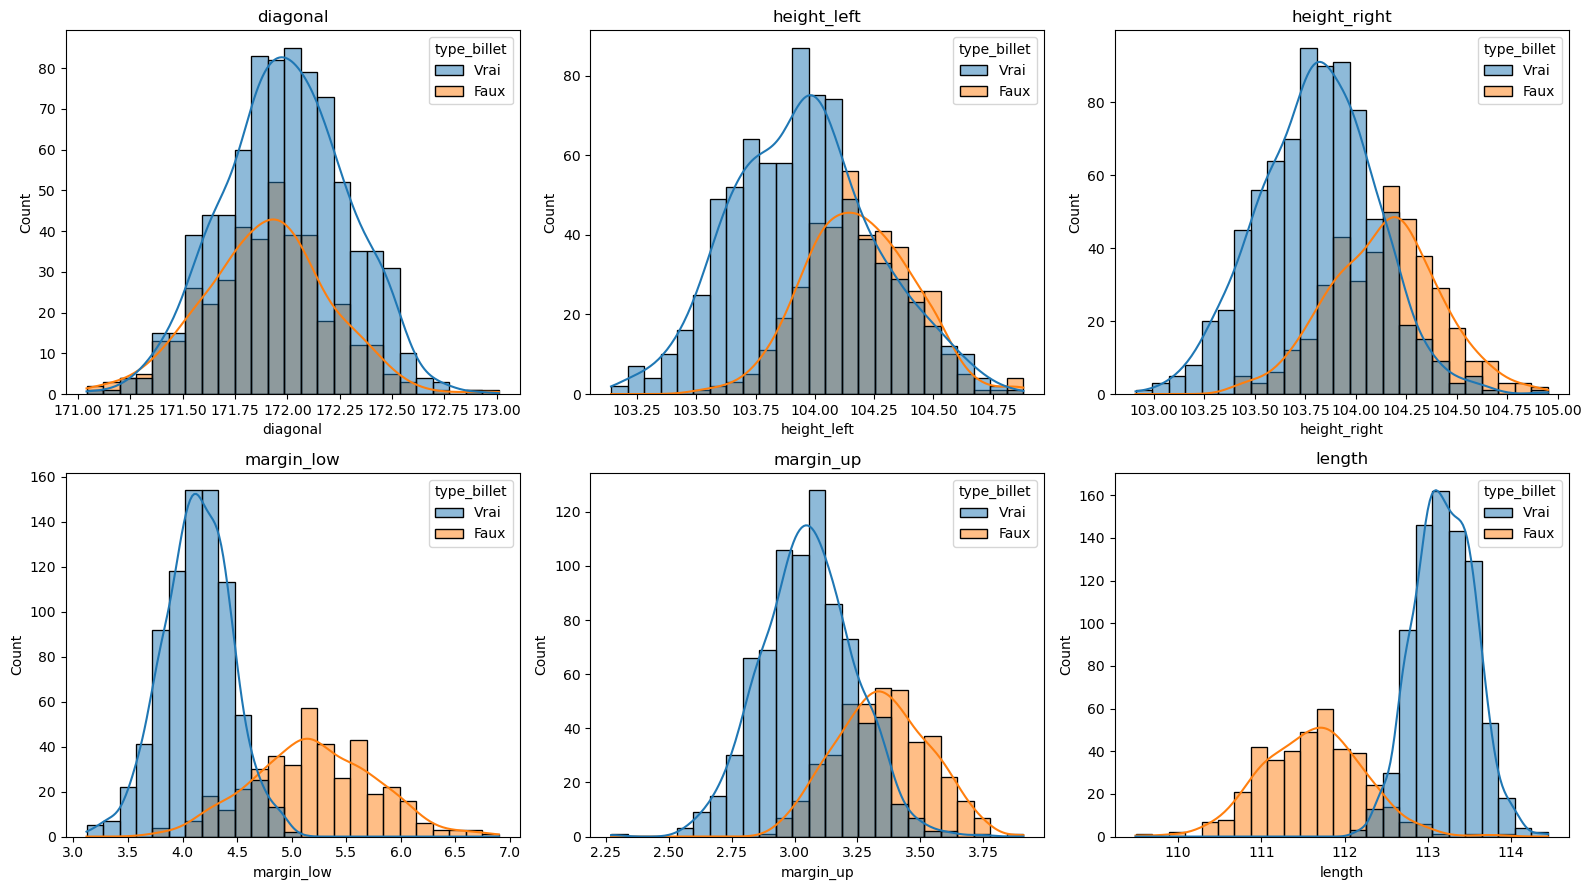

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, variable in zip(axes.flatten(), features):
    sns.histplot(
        data=eda,
        x=variable,
        hue="type_billet",
        bins=25,
        kde=True,
        ax=ax
    )
    ax.set_title(variable)

plt.tight_layout()
# plt.savefig("histplot1.png", dpi=300, bbox_inches="tight")
plt.show()

les **vrais billets** ont tendance à être **plus longs**, tandis que les **faux billets** ont en moyenne des **marges inférieure et supérieure plus grandes.**
height_left et height_right apportent également de l’information, mais la séparation est moins spectaculaire. La diagonal semble beaucoup plus proche entre les deux groupes.

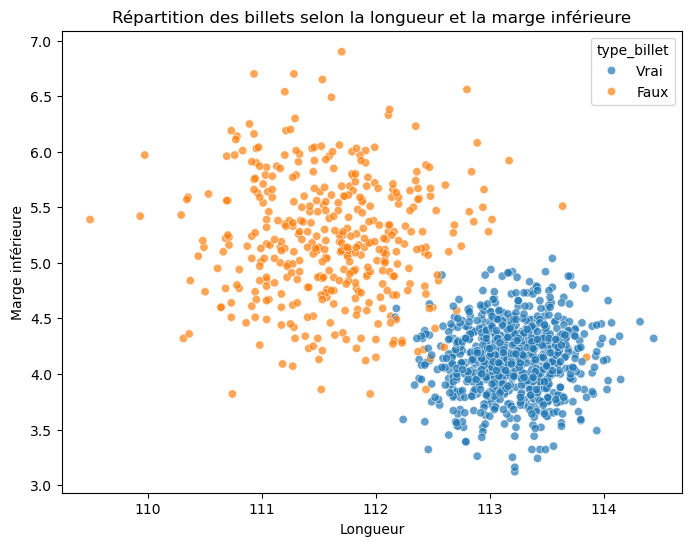

In [19]:
# un seul graphique à deux dimensions
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=eda,
    x="length",
    y="margin_low",
    hue="type_billet",
    alpha=0.7
)

plt.title("Répartition des billets selon la longueur et la marge inférieure")
plt.xlabel("Longueur")
plt.ylabel("Marge inférieure")
#plt.savefig("nuage1.png", dpi=300, bbox_inches="tight")
plt.show()

Ce graphique est particulièrement utile parce qu’il permet de voir visuellement si deux variables suffisent déjà à faire apparaître des groupes. C’est aussi une bonne transition vers le K-means, puisque celui-ci cherchera justement des regroupements sans utiliser la variable cible.

Enfin, regardons les corrélations numériques :

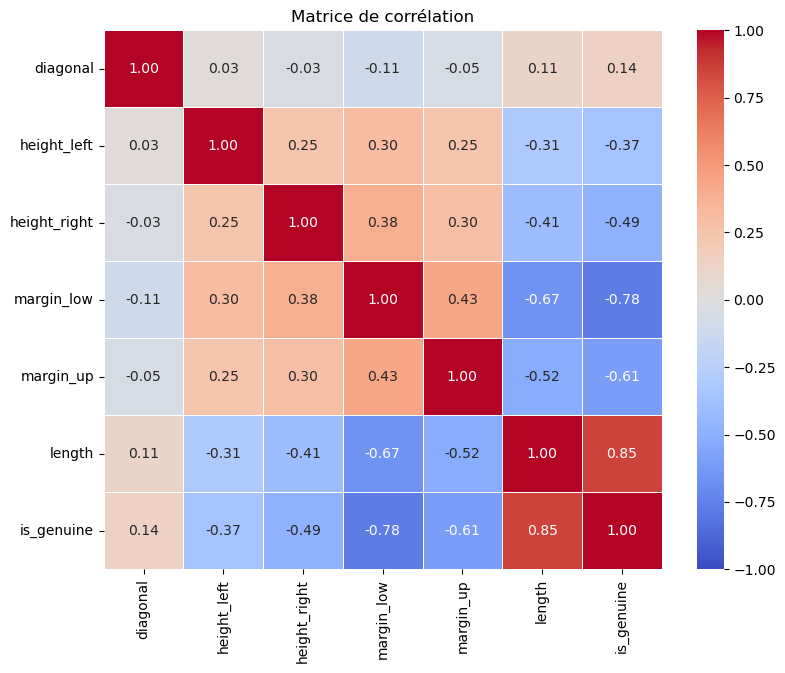

In [20]:
eda_corr = eda[features + ["is_genuine"]].copy()
eda_corr["is_genuine"] = eda_corr["is_genuine"].astype(int)

plt.figure(figsize=(9, 7))

sns.heatmap(
    eda_corr.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Matrice de corrélation")
plt.show()

## <span style="color: magenta;">3 - La régression logistique </span>

### <span style="color: magenta;"> - Standardisation</span>

StandardScaler transforme chaque variable pour qu’elle soit centrée autour de 0 et ait un écart-type proche de 1.

In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

on pose 1 = fake et 0 = genuine, ce qui est pratique puisque notre priorité est la détection des faux billets.

In [22]:
y_train_fake = (~y_train).astype(int)
y_test_fake = (~y_test).astype(int)

### <span style="color: magenta;"> - Regression</span>

In [23]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(random_state=42)

log_reg.fit(X_train_scaled, y_train_fake)

y_pred_log = log_reg.predict(X_test_scaled)

**Evaluation**

On commence avec l’accuracy et la matrice de confusion

In [24]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test_fake, y_pred_log))

print("\nConfusion matrix:")
print(confusion_matrix(y_test_fake, y_pred_log))

print("\nClassification report:")
print(classification_report(
    y_test_fake,
    y_pred_log,
    target_names=["genuine", "fake"]
))

Accuracy: 0.99

Confusion matrix:
[[199   1]
 [  2  98]]

Classification report:
              precision    recall  f1-score   support

     genuine       0.99      0.99      0.99       200
        fake       0.99      0.98      0.98       100

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300



199 vrais billets correctement reconnus ;
1 vrai billet classé à tort comme faux ;
98 faux billets correctement détectés ;
2 faux billets classés à tort comme vrais.

La régression logistique obtient une accuracy de 99 %. Sur les 100 faux billets du jeu de test, 98 sont correctement détectés et 2 sont classés à tort comme authentiques. Le rappel de la classe fake atteint donc 98 %.

## <span style="color: Turquoise;">4 - K-means</span>

l’idée est de voir si les dimensions géométriques des billets forment naturellement deux groupes, sans dire au modèle lesquels sont vrais ou faux.

On divise d'abord notre echantillon train en **deux clusters**. en suite, on regarde les centroiodes et les etiquettes. puis, on décide pour chaque nouveau billet si il est plus proche du centroide de vrai ou de faux. 

On fait d’abord le K-means sur le train uniquement, puis on regarde ce qu’il a réellement regroupé avant de calculer ses performances.

In [25]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

train_clusters = kmeans.fit_predict(X_train_scaled)

In [26]:
pd.crosstab(
    train_clusters,
    y_train_fake,
    rownames=["cluster"],
    colnames=["actual"]
)

actual,0,1
cluster,,
0,6,388
1,794,12


On peut conclure : cluster 0 → fake (1) ; 
cluster 1 → genuine (0)

Maintenant, on utilise les centroïdes appris sur le train pour classer les 300 billets du test

In [27]:
test_clusters = kmeans.predict(X_test_scaled)

y_pred_kmeans = np.where(test_clusters == 0, 1, 0)

Puis exactement la même évaluation que pour la régression logistique

In [28]:
print("Accuracy:", accuracy_score(y_test_fake, y_pred_kmeans))

print("\nConfusion matrix:")
print(confusion_matrix(y_test_fake, y_pred_kmeans))

print("\nClassification report:")
print(classification_report(
    y_test_fake,
    y_pred_kmeans,
    target_names=["genuine", "fake"]
))

Accuracy: 0.9866666666666667

Confusion matrix:
[[198   2]
 [  2  98]]

Classification report:
              precision    recall  f1-score   support

     genuine       0.99      0.99      0.99       200
        fake       0.98      0.98      0.98       100

    accuracy                           0.99       300
   macro avg       0.98      0.98      0.98       300
weighted avg       0.99      0.99      0.99       300



198 genuine correctement classés ; 
2 genuine classés comme fake ; 
98 fake correctement détectés ; 
2 fake classés comme genuine ;

Donc le rappel sur les faux billets est encore de 98 %, comme pour la régression logistique.


La régression logistique reste très légèrement meilleure. La différence vient d’un seul billet supplémentaire mal classé par K-means. Sur la détection des faux billets, en revanche, les deux modèles font exactement pareil : 98 faux détectés sur 100.

## <span style="color:Chocolate;">5 - KNN</span>

Comme les données sont déjà standardisées, on peut entraîner directement un KNN simple avec k=5.

In [29]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train_fake)

y_pred_knn = knn.predict(X_test_scaled)

Puis on l’évalue exactement comme les deux modèles précédents :

In [30]:
print("Accuracy:", accuracy_score(y_test_fake, y_pred_knn))

print("\nConfusion matrix:")
print(confusion_matrix(y_test_fake, y_pred_knn))

print("\nClassification report:")
print(classification_report(
    y_test_fake,
    y_pred_knn,
    target_names=["genuine", "fake"]
))

Accuracy: 0.9833333333333333

Confusion matrix:
[[198   2]
 [  3  97]]

Classification report:
              precision    recall  f1-score   support

     genuine       0.99      0.99      0.99       200
        fake       0.98      0.97      0.97       100

    accuracy                           0.98       300
   macro avg       0.98      0.98      0.98       300
weighted avg       0.98      0.98      0.98       300



C’est encore très bon, mais un peu moins bon que les deux précédents. on a 198 vrais billets correctement reconnus, 2 vrais classés comme faux, 97 faux correctement détectés et surtout 3 faux classés comme vrais.

On pourrait optimiser k plus tard, mais d'abord voyons le Random Forest

## <span style="color: BlueViolet;">6 - Random Forest</span>

Chaque arbre prend sa décision, puis la forêt fait voter l’ensemble. Ici, on utilisera directement les données imputées, sans standardisation, car les arbres ne dépendent pas de la distance entre les variables.

In [31]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train_imputed, y_train_fake)

y_pred_rf = rf.predict(X_test_imputed)

Puis on l’évalue comme les autres :

In [32]:
print("Accuracy:", accuracy_score(y_test_fake, y_pred_rf))

print("\nConfusion matrix:")
print(confusion_matrix(y_test_fake, y_pred_rf))

print("\nClassification report:")
print(classification_report(
    y_test_fake,
    y_pred_rf,
    target_names=["genuine", "fake"]
))

Accuracy: 0.99

Confusion matrix:
[[199   1]
 [  2  98]]

Classification report:
              precision    recall  f1-score   support

     genuine       0.99      0.99      0.99       200
        fake       0.99      0.98      0.98       100

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300



le Random Forest obtient exactement les mêmes résultats que la régression logistique sur le jeu de test

|Logistic Regression : accuracy 0.99 — recall fake 0.98 — 2 faux ratés|
|Random Forest        : accuracy 0.99 — recall fake 0.98 — 2 faux ratés|
|K-means              : accuracy 0.9867 — recall fake 0.98 — 2 faux ratés|
|KNN                  : accuracy 0.9833 — recall fake 0.97 — 3 faux ratés|

## <span style="color:DodgerBlue; "> 7 - Comparer les 4 modèles </span>

Rassembler les quatre résultats dans un petit tableau

In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models_results = pd.DataFrame({
    "model": ["Logistic Regression", "K-means", "KNN", "Random Forest"],
    "accuracy": [
        accuracy_score(y_test_fake, y_pred_log),
        accuracy_score(y_test_fake, y_pred_kmeans),
        accuracy_score(y_test_fake, y_pred_knn),
        accuracy_score(y_test_fake, y_pred_rf)
    ],
    "precision_fake": [
        precision_score(y_test_fake, y_pred_log),
        precision_score(y_test_fake, y_pred_kmeans),
        precision_score(y_test_fake, y_pred_knn),
        precision_score(y_test_fake, y_pred_rf)
    ],
    "recall_fake": [
        recall_score(y_test_fake, y_pred_log),
        recall_score(y_test_fake, y_pred_kmeans),
        recall_score(y_test_fake, y_pred_knn),
        recall_score(y_test_fake, y_pred_rf)
    ],
    "f1_fake": [
        f1_score(y_test_fake, y_pred_log),
        f1_score(y_test_fake, y_pred_kmeans),
        f1_score(y_test_fake, y_pred_knn),
        f1_score(y_test_fake, y_pred_rf)
    ]
})

models_results.round(3)

,model,accuracy,precision_fake,recall_fake,f1_fake
0,Logistic Regression,0.990,0.99,0.98,0.985
1,K-means,0.987,0.98,0.98,0.980
2,KNN,0.983,0.98,0.97,0.975
3,Random Forest,0.990,0.99,0.98,0.985


### <span style="color:DodgerBlue; "> - Vérification de la stabilité croisée des modèles </span>

On fait d’abord une validation croisée uniquement sur les 1 200 billets du train. On garde les 300 billets test totalement à part.

L’idée : on découpe le train en 5 morceaux. Le modèle apprend sur 4 morceaux et est évalué sur le 5e, puis on recommence 5 fois. Cela permet de voir si les performances sont stables et pas seulement bonnes sur un découpage particulier.

In [35]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

log_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(random_state=42)
)

rf_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(n_estimators=100, random_state=42)
)

models = {
    "Logistic Regression": log_model,
    "Random Forest": rf_model
}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train_fake,
        cv=cv,
        scoring=["accuracy", "precision", "recall", "f1"]
    )

    print(name)
    print("Accuracy :", scores["test_accuracy"].mean().round(3))
    print("Precision:", scores["test_precision"].mean().round(3))
    print("Recall   :", scores["test_recall"].mean().round(3))
    print("F1-score :", scores["test_f1"].mean().round(3))
    print()

Logistic Regression
Accuracy : 0.992
Precision: 0.995
Recall   : 0.982
F1-score : 0.989

Random Forest
Accuracy : 0.991
Precision: 0.993
Recall   : 0.98
F1-score : 0.986



On regarde maintenant les probabilités de prédiction des deux meilleurs modèles.

Pour la régression logistique :

In [36]:
proba_log = log_reg.predict_proba(X_test_scaled)[:, 1]

Pour la Random Forest :

In [37]:
proba_rf = rf.predict_proba(X_test_imputed)[:, 1]

On peut rassembler le tout

In [38]:
results_test = pd.DataFrame({
    "actual": y_test_fake,
    "pred_log": y_pred_log,
    "proba_log": proba_log,
    "pred_rf": y_pred_rf,
    "proba_rf": proba_rf
})

results_test.head()

,actual,pred_log,proba_log,pred_rf,proba_rf
803,0,0,0.000991,0,0.01
1306,1,1,0.999976,1,1.00
1263,1,1,0.999975,1,1.00
38,0,0,0.359895,0,0.05
257,0,0,0.002342,0,0.00


In [40]:
results_test.shape

(300, 5)

Ensuite, regardons surtout les erreurs :

Comme les deux modèles avaient exactement la même matrice de confusion, ce qui devient intéressant maintenant est de voir s’ils se trompent sur les mêmes billets et avec quel niveau de confiance.

In [41]:
results_test[
    (results_test["pred_log"] != results_test["actual"]) |
    (results_test["pred_rf"] != results_test["actual"])
]

,actual,pred_log,proba_log,pred_rf,proba_rf
728,0,1,0.924923,1,0.87
1190,1,0,0.478142,0,0.26
1160,1,0,0.323895,0,0.26


On peut aussi trier les billets les plus incertains pour la régression logistique. Les premières lignes seront les billets dont la probabilité est la plus proche de 0.5, donc les cas les plus difficiles à classer.

In [42]:
results_test["uncertainty_log"] = abs(results_test["proba_log"] - 0.5)

results_test.sort_values("uncertainty_log").head(10)

,actual,pred_log,proba_log,pred_rf,proba_rf,uncertainty_log
1190,1,0,0.478142,0,0.26,0.021858
1121,1,1,0.559415,1,0.53,0.059415
341,0,0,0.409840,0,0.18,0.090160
38,0,0,0.359895,0,0.05,0.140105
1160,1,0,0.323895,0,0.26,0.176105
441,0,0,0.265492,0,0.07,0.234508
1482,1,1,0.804127,1,0.77,0.304127
1315,1,1,0.824980,1,0.87,0.324980
392,0,0,0.173182,0,0.22,0.326818
1252,1,1,0.852482,1,0.93,0.352482


Les deux modèles se trompent sur exactement les mêmes 3 billets : le billet 728 est genuine mais prédit fake, tandis que les billets 1190 et 1160 sont fake mais prédits genuine.

La régression logistique et la Random Forest obtiennent les mêmes erreurs sur le jeu de test. La validation croisée donne toutefois un léger avantage à la régression logistique, avec une accuracy moyenne de 0,992 contre 0,991 et un rappel de 0,982 contre 0,980. L’analyse des probabilités montre également que l’un des faux billets mal classés par la régression logistique se situe très près du seuil de décision de 0,5.

on a maintenant suffisamment d’éléments pour retenir la régression logistique comme modèle final

La prochaine étape est de construire le pipeline final de régression logistique, puis de l’entraîner sur les 1 500 billets afin de préparer le script qui recevra les futurs billets.

## <span style="color:DarkOrange;"> 8 - Algorithme finale </span>

### <span style="color:DarkOrange;"> - Pipleline </span>

On passe donc au modèle final. Maintenant que la régression logistique a été retenue, on peut la réentraîner sur les 1 500 billets afin qu’elle profite de toutes les données disponibles. Le jeu test a déjà rempli son rôle pour comparer les modèles.

On va mettre l’imputation, la standardisation et la régression logistique dans un seul Pipeline. Le futur script pourra recevoir des données brutes et appliquer automatiquement exactement les mêmes traitements.

In [44]:
from sklearn.pipeline import Pipeline

X = df.drop(columns="is_genuine")
y = (~df["is_genuine"]).astype(int)

final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=42))
])

final_model.fit(X, y)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier', LogisticRegression(random_state=42))])

avec 0 = genuine ; 
1 = fake

on sauvegarde le modèle

In [45]:
import joblib

joblib.dump(final_model, "billet_model.pkl")

['billet_model2.pkl']

Le fichier billet_model.pkl contiendra tout : la médiane apprise pour les valeurs manquantes, la standardisation et la régression logistique.

In [46]:
# vérifier
model = joblib.load("billet_model.pkl")

model.predict(X.head())

array([0, 0, 0, 0, 0])

### <span style="color:DarkOrange;"> - Mise en production du modèle final</span>

Jusqu’ici, on avait séparé les données en train/test pour évaluer les modèles. Maintenant que le choix est fait, on peut entraîner le modèle final sur toutes les 1500 données disponibles.

In [47]:
X = df.drop(columns="is_genuine")
y = (~df["is_genuine"]).astype(int)

on crée un Pipeline :

In [50]:
from sklearn.pipeline import Pipeline

#remplit automatiquement une éventuelle valeur manquante
#standardise les six dimensions
#fait la prédiction finale

final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=42))
])

Ensuite, on entraîne le pipeline :

In [51]:
final_model.fit(X, y)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier', LogisticRegression(random_state=42))])

Ensuite, on sauvegarde le modèle :

In [49]:
import joblib

joblib.dump(final_model, "billet_model.pkl")

['billet_model2.pkl']

ce fichier contient maintenant notre modèle complet. Il mémorise notamment la médiane utilisée pour l'imputation, les paramètres de standardisation et les coefficients appris par la régression logistique.